## 1. Tensor 마스터하기

### 텐서 생성

In [ ]:
import torch

#0으로 채우기
zeros=torch.zeros(2,3)
print(zeros)

#1로 채우기
ones=torch.ones(3,4)
print(ones)

#0~1 랜덤 값으로 채우기
randn=torch.rand(2,2)
print(randn)

#리스트로 만들기
tensor=torch.tensor([1,2,3])
print(tensor)

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([[0.2631, 0.5432],
        [0.3603, 0.1677]])
tensor([1, 2, 3])


### 사칙연산

In [ ]:
#사칙연산
a=torch.tensor([1,2,3,4])
b=torch.tensor([3,4,5,6])
print(a+b)
print(a-b)
print(a*b)
print(a/b)

a=torch.tensor([[1,2,3,4],
               [2,3,4,5]])
b=torch.tensor([[3,4],
               [5,6],
               [1,2],
               [3,4]])
#행렬곱
print(a@b)
#브로드캐스팅
a=torch.tensor([[1,2,3],
                [4,5,6]])
b=torch.tensor([5,6,7])
print(a+b)

tensor([ 4,  6,  8, 10])
tensor([-2, -2, -2, -2])
tensor([ 3,  8, 15, 24])
tensor([0.3333, 0.5000, 0.6000, 0.6667])
tensor([[28, 38],
        [40, 54]])
tensor([[ 6,  8, 10],
        [ 9, 11, 13]])


In [ ]:
a=torch.tensor([[1,2,3],
                [4,5,6]])
c=torch.tensor([[1,2],
                [2,3]])
print(a+c)

RuntimeError: The size of tensor a (3) must match the size of tensor b (2) at non-singleton dimension 1

## 2. Autograd 체험하기

In [ ]:
'''requires_grad란?
True로 설정할 경우 해당 변수가 사용된 연산을 저장'''
x = torch.tensor(2.0, requires_grad=True)
y=x**2+3*x
y.backward()
print(y.item())
print(x.grad.item())

10.0
7.0


### nn.Module 로 나만의 모델 설계하기

In [ ]:
import torch.nn as nn
import torch
class SimpleLinearModel(nn.Module):
    def __init__(self):
        super().__init__()#.to(), .eval(), train(), save() 등 메서드 활성화
        #선형 레이어 객체 생성(입력 특성의 수, 출력 특성의 수)
        self.linear = nn.Linear(1, 10)

    #레이어 객체 생성 및 선형 연산 수행
    def forward(self, x):
        x = x.flatten(start_dim=1)#데이터를 1차원으로 펼침
        print('forward 호출됨')
        return self.linear(x)

### GPU 활용 맛보기


In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
x=torch.tensor([[2.0]])
x=x.to(device)
print(x.device)

cuda:0


In [ ]:
model=SimpleLinearModel()
model=model.to(device)
prediction=model(x)#forward 호출

forward 호출됨


In [ ]:
import time
size=5000

#CPU 사용
cpu_device=torch.device("cpu")
a_cpu=torch.randn(size,size).to(cpu_device)
b_cpu=torch.randn(size,size).to(cpu_device)

start=time.time()
result_cpu=a_cpu@b_cpu
cpu_time=time.time()-start
print(f"CPU 시간: {cpu_time:.4f}")

#GPU 사용
if torch.cuda.is_available():
  gpu_device=torch.device("cuda")

  a_gpu=a_cpu.to(gpu_device)
  b_gpu=b_cpu.to(gpu_device)

  torch.cuda.synchronize()#gpu작업 대기
  start=time.time()

  result_gpu=a_gpu@b_gpu

  torch.cuda.synchronize()#gpu는 비동기로 작동
  gpu_time=time.time()-start

  print(f"GPU 시간: {gpu_time:.4f}")
else:
  print("gpu사용 불가")


CPU 시간: 2.0778
GPU 시간: 0.1930


### 기본 훈련 루프 완성하기

In [ ]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

dataset = datasets.FakeData(
    size=1000,                   # 데이터 개수
    image_size=(3, 32, 32),      # 채널(3인 경우 RGB, 1이면 흑백), 높이, 너비
    num_classes=10,              # 클래스 개수
    transform=transform
)

#batch_size 한 번에 모델에 넣을 데이터의 크기
loader = DataLoader(dataset, batch_size=32, shuffle=True)

model=SimpleLinearModel().to(device)


epochs = 10

for epoch in range(epochs):
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        output = model(x)#순전파
        loss = criterion(output, y)#오차 계산

        optimizer.zero_grad()#이전 배치의 미분값 초기화
        loss.backward()#역전파
        optimizer.step()#가중치 수정

    print(f"Epoch {epoch + 1}/{epochs}, loss: {loss.item():.4f}")


Epoch 1/10, loss: 2.2881
Epoch 2/10, loss: 2.2110
Epoch 3/10, loss: 2.3636
Epoch 4/10, loss: 2.3692
Epoch 5/10, loss: 2.4730
Epoch 6/10, loss: 2.4302
Epoch 7/10, loss: 2.3009
Epoch 8/10, loss: 2.3767
Epoch 9/10, loss: 2.3391
Epoch 10/10, loss: 2.2849


## 2. 이미지 증강 직접 만들기

### 좌우반전

In [ ]:
from PIL import Image
import numpy as np
import torch

#이미지 불러오기
img = Image.open("sample_data/img1.png").convert("RGB")
#넘파이로 변환
arr = np.array(img)

Inverted_arr=arr.copy()
col=len(Inverted_arr[0])
row=len(Inverted_arr)
for i in range(row):
  for j in range(col//2):
    temp=Inverted_arr[i][j].copy()
    Inverted_arr[i][j]=Inverted_arr[i][col-j-1]
    Inverted_arr[i][col-j-1]=temp
import matplotlib.pyplot as plt

plt.imshow(Inverted_arr)
plt.axis("off")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'sample_data/img1.png'

### 상하반전

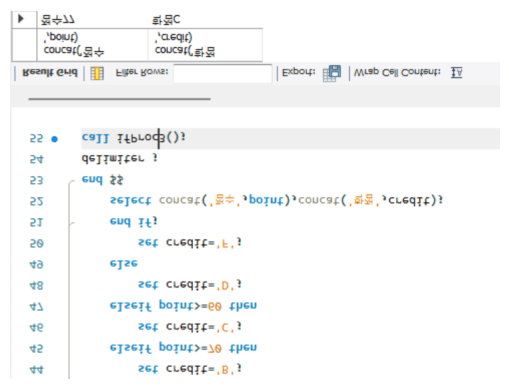

In [ ]:
Inverted_arr=arr.copy()
for i in range(row//2):
  for j in range(col):
    temp=Inverted_arr[i][j].copy()
    Inverted_arr[i][j]=Inverted_arr[row-i-1][j]
    Inverted_arr[row-i-1][j]=temp
import matplotlib.pyplot as plt

plt.imshow(Inverted_arr)
plt.axis("off")
plt.show()

### 회전

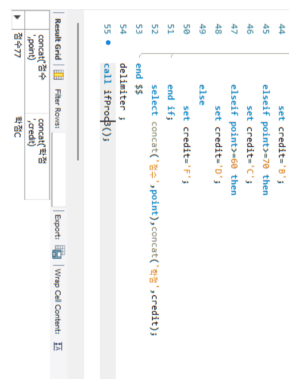

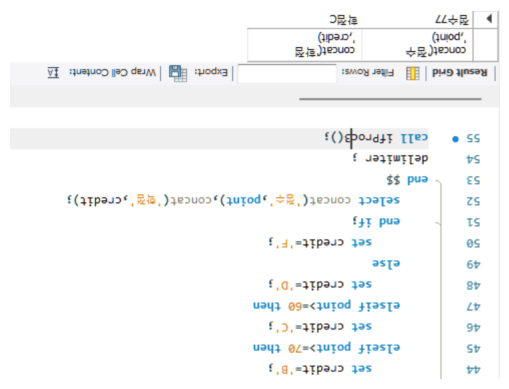

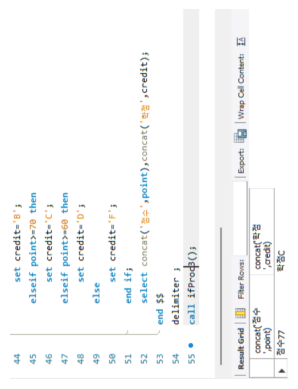

In [ ]:
#90도
rotated_arr=np.zeros((col,row,3),dtype=np.uint8)

for i in range(row):
  for j in range(col):
    rotated_arr[j][row-1-i]=arr[i][j].copy()

plt.imshow(rotated_arr)
plt.axis("off")
plt.show()

#180도
rotated_arr=np.zeros((row,col,3),dtype=np.uint8)

for i in range(row):
  for j in range(col):
    rotated_arr[row-1-i][j]=arr[i][col-1-j].copy()

plt.imshow(rotated_arr)
plt.axis("off")
plt.show()

#270도
rotated_arr=np.zeros((col,row,3),dtype=np.uint8)

for i in range(row):
  for j in range(col):
    rotated_arr[col-1-j][i]=arr[i][j].copy()

plt.imshow(rotated_arr)
plt.axis("off")
plt.show()

### 밝기 조절

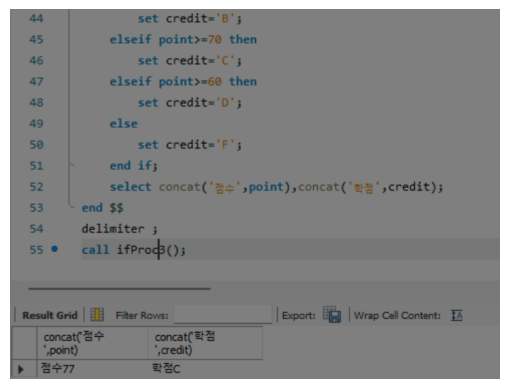

In [ ]:
arr = np.array(img)
brightness=0.5
for i in range(row):
  for j in range(col):
    for k in range(3):
      arr[i][j][k]=arr[i][j][k]*brightness

plt.imshow(arr)
plt.axis("off")
plt.show()

### 랜덤 크롭

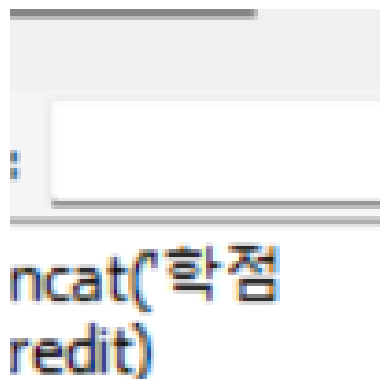

In [ ]:

arr = np.array(img)
size=100

new_x=np.random.randint(0,row-size)
new_y=np.random.randint(0,col-size)

cropped_arr=arr[new_x:new_x+size,new_y:new_y+size]

plt.imshow(cropped_arr)
plt.axis("off")
plt.show()

In [ ]:
class Compose:
  def __init__(self,transforms):
    self.transforms=transforms
  def __call__(self,img):
    for transfrom in self.transforms:
      img=transfrom(img)
    return img
class RandomCrop:
  def __init__(self,size):
    self.size=size
  def __call__(self,img):
    arr=np.array(img)
    row=len(arr)
    col=len(arr[0])
    new_x=np.random.randint(0,row-self.size)
    new_y=np.random.randint(0,col-self.size)
    arr=arr[new_x:new_x+self.size,new_y:new_y+self.size]
    return Image.fromarray(arr)
class HorizontalInversion:
  def __call__(self,img):
    arr=np.array(img)
    row=len(arr)
    col=len(arr[0])
    for i in range(row):
      for j in range(col//2):
        temp=arr[i][j].copy()
        arr[i][j]=arr[i][col-j-1]
        arr[i][col-j-1]=temp
    return Image.fromarray(arr)
class VerticalInversion:
  def __call__(self,img):
    arr=np.array(img)
    row=len(arr)
    col=len(arr[0])
    for i in range(row//2):
      for j in range(col):
        temp=arr[i][j].copy()
        arr[i][j]=arr[row-i-1][j]
        arr[row-i-1][j]=temp
    return Image.fromarray(arr)
class Rotation:
  def __init__(self,degree):
    self.degree=degree
  def __call__(self,img):
    arr=np.array(img)
    row=len(arr)
    col=len(arr[0])
    if self.degree==90:
      new_arr=np.zeros((col,row,3),dtype=np.uint8)
      for i in range(row):
        for j in range(col):
          new_arr[j][row-1-i]=arr[i][j].copy()
      return Image.fromarray(new_arr)
    elif self.degree==180:
      new_arr=np.zeros((row,col,3),dtype=np.uint8)
      for i in range(row):
        for j in range(col):
          new_arr[row-1-i][j]=arr[i][col-1-j].copy()
      return Image.fromarray(new_arr)
    elif self.degree==270:
      new_arr=np.zeros((col,row,3),dtype=np.uint8)
      for i in range(row):
        for j in range(col):
          new_arr[col-1-j][i]=arr[i][j].copy()
      return Image.fromarray(new_arr)
    else:
      print("degree error")
    return Image.fromarray(arr)
class BrightnessAdjustment:
  def __init__(self,brightness):
    self.brightness=brightness
  def __call__(self,img):
    arr=np.array(img)
    row=len(arr)
    col=len(arr[0])
    for i in range(row):
      for j in range(col):
        for k in range(3):
          arr[i][j][k]=arr[i][j][k]*self.brightness
    return Image.fromarray(arr)


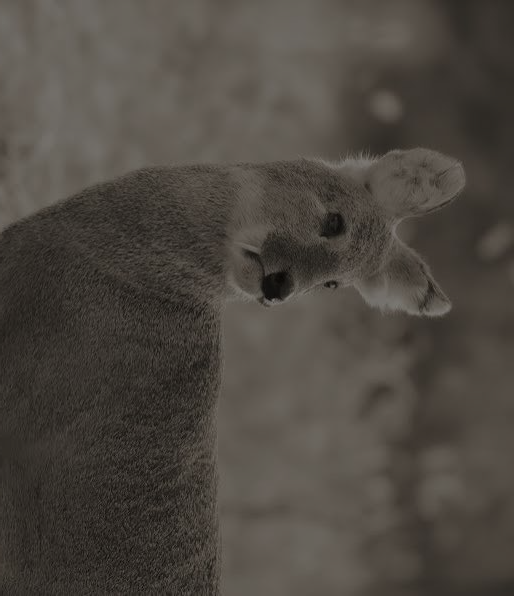

In [ ]:
import time
img = Image.open("sample_data/고라니.jfif").convert("RGB")
pipeline=Compose([BrightnessAdjustment(0.5),VerticalInversion(),HorizontalInversion(),Rotation(90),Rotation(180)])
display(pipeline(img))
# arr = np.array(img)
# aument=ImageAugmentation(arr)
# #plt.imshow(arr)
# plt.imshow(aument.rotation(270).random_crop(300).arr)
# plt.axis("off")

### torchvision과 비교

In [ ]:
import torch
import torchvision.transforms.v2 as v2

import time
#직접 구현
img = Image.open("sample_data/고라니.jfif").convert("RGB")
pipeline=Compose([VerticalInversion()])
start=time.time()
pipeline(img)
end=time.time()
print(f"직접 구현: {end-start:.4}")

#torchvision
pipeline2 = v2.Compose([
    v2.RandomVerticalFlip(p=1.0),
])
device='cpu'
img_tensor = v2.functional.to_image(img)
img_tensor = v2.functional.to_dtype(img_tensor, dtype=torch.float32, scale=True)

start=time.time()
result_tensor = pipeline2(img_tensor)
end=time.time()
print(f"torchvision: {end-start:.4}")

직접 구현: 0.2745
torchvision: 0.001055


### CPU, GPU 비교

In [ ]:
import torch
import torchvision.transforms.v2 as v2
import time

pipeline2 = v2.Compose([
    v2.RandomHorizontalFlip(p=1.0),
    v2.RandomVerticalFlip(p=1.0),
])

#CPU 측정
start = time.time()
res_cpu = pipeline2(img)
print(f"CPU 처리 시간: {time.time() - start:.4f}초")


#GPU 측정
_ = pipeline(img)
torch.cuda.synchronize()
start = time.time()
res_gpu = pipeline2(img)
torch.cuda.synchronize()
print(f"GPU 처리 시간: {time.time() - start:.4f}초")

CPU 처리 시간: 0.0014초
GPU 처리 시간: 0.0013초


### GPU, CPU 비교(배치 크기 조정)

In [ ]:
for batch_size in [32,64,128,256,512]:
  batch_cpu = torch.randn(batch_size, 3, 256, 256)
  batch_gpu = batch_cpu.to('cuda')

  #CPU 측정
  start = time.time()
  res_cpu = pipeline2(batch_cpu)
  print(f"CPU 처리 시간({batch_size}): {time.time() - start:.4f}초")

  #GPU 측정
  _ = pipeline(img)
  torch.cuda.synchronize()
  start = time.time()
  res_gpu = pipeline2(batch_gpu)
  torch.cuda.synchronize()
  print(f"GPU 처리 시간({batch_size}): {time.time() - start:.4f}초")

CPU 처리 시간(32): 0.0269초
GPU 처리 시간(32): 0.0402초
CPU 처리 시간(64): 0.0548초
GPU 처리 시간(64): 0.0013초
CPU 처리 시간(128): 0.1017초
GPU 처리 시간(128): 0.0025초
CPU 처리 시간(256): 0.2196초
GPU 처리 시간(256): 0.0042초
CPU 처리 시간(512): 0.8259초
GPU 처리 시간(512): 0.0102초


## 3. 고양이 강아지 분류 모델

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
from pathlib import Path
from PIL import Image
import kagglehub

class CustomDataset:
  def __init__(self,root_dir,label_map,transform):
    self.root_dir=root_dir
    self.label_map=label_map
    self.samples=[]
    self.transform=transform
    for class_name,label in label_map.items():
      class_dir=self.root_dir/class_name
      for img_path in class_dir.glob("*.jpg"):
        self.samples.append((img_path,label))
  def __len__(self):
    return len(self.samples)
  def __getitem__(self,idx):
    img_path,label=self.samples[idx]
    img=Image.open(img_path).convert("RGB")
    if self.transform:
      img=self.transform(img)
    return img,label
class SimpleLinearModel(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 2)#(입력, 출력)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        return self.linear(x)


### 모델 학습

In [ ]:
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
root_dir = Path(path) / "PetImages"
label_map = {"Cat": 0, "Dog": 1}

transform = transforms.Compose([
    transforms.Resize((224, 224)),#이미지 크기 변환
    transforms.ToTensor()#이미지를 텐서로 변환, 픽셀(0~255)을 실수(0~1)로 변환
])
dataset = CustomDataset(root_dir, label_map,transform)#(데이터 경로, 이름과 정답 매핑, 이미지에 적용할 전처리)

loader = DataLoader(dataset, batch_size=32, shuffle=True)#데이터를 배치 수만큼 추출, 섞기

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleLinearModel(224*224*3).to(device)#모델을 GPU에 전달
criterion = nn.CrossEntropyLoss()#손실함수 교차 엔트로피 - 틀린 정답일수록 벌점을 무겁게(가파르게) 적용
optimizer = optim.Adam(model.parameters(), lr=0.001)#모델 최적화, lr(learning rate) - 학습률:경사를 따라 얼만큼 빨리 이동할 것인가?

epochs = 5

for epoch in range(epochs):
    model.train()#모델을 학습 전용으로 변경
    running_loss = 0.0

    for x, y in loader:# x - 4차원 텐서(32,3,32,32) y - 길이 32의 1차원 텐서
        x = x.to(device)
        y = y.to(device)

        #1. 순전파
        output = model(x)
        #2. 손실 함수
        loss = criterion(output, y)
        #3. 역전파
        optimizer.zero_grad()#가중치 변수 내부의 미분값(기울기)를 0으로 초기화
        loss.backward()#기울기 계산
        #4. 가중치 업데이트
        optimizer.step()#계산된 기울기를 바탕으로 가중치 변경

        running_loss += loss.item() * x.size(0)#배치들의 평균 손실 값 * 배치 수

    epoch_loss = running_loss / len(dataset)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.4f}")
torch.save(model.state_dict(), "model_weights.pth")

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Epoch 1/5, Loss: 5.0398
Epoch 2/5, Loss: 4.2069
Epoch 3/5, Loss: 4.9999
Epoch 4/5, Loss: 4.1030
Epoch 5/5, Loss: 4.6488


### 모델 불러오기, 예측

In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms
from PIL import Image

# 장치 설정 (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleLinearModel(3 * 224 * 224).to(device)

#가중치 불러오기
model_path = "model_weights.pth"  # 저장했던 .pth 파일 경로
model.load_state_dict(torch.load(model_path, map_location=device))#가중치를 읽어 모델의 레이어에 대입

model.eval()#평가 모드로 전환

#이미지 전처리
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

def predict_image(image_path, model, transform, label_map):
    img = Image.open(image_path).convert("RGB")

    #이미지->텐서 변환, 배치 차원 추가, GPU로 이동
    img_tensor = transform(img).unsqueeze(0).to(device)

    #예측
    with torch.no_grad():#학습이 아니므로 기울기 추척하지 않음
        outputs = model(img_tensor)#예측 결과

        probabilities = torch.softmax(outputs, dim=1)#결과를 0~1로 변환

        confidence, predicted_idx = torch.max(probabilities, dim=1)#가장 높은 확률, 인덱스 추출

    idx_to_label = {v: k for k, v in label_map.items()}
    predicted_label = idx_to_label[predicted_idx.item()]

    return predicted_label, confidence.item() * 100

label_map = {"Cat": 0, "Dog": 1}
test_image_path = "dog3.jfif"

#예측 실행
predicted_class, prob = predict_image(test_image_path, model, transform, label_map)

print(f"예측 결과: {predicted_class} (확신도: {prob:.2f}%)")

예측 결과: Dog (확신도: 57.91%)
